In [1]:
import os, sys
import scipy
import pandas as pd
pd.set_option('display.max_rows', None)
import scanpy as sc
# import dask
import squidpy as sq
import numpy as np
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RUNID=4
#BASE_DIR = f'/nfs/team361/aa36/OnGit/inflow-reproducibility/Analysis/18_Melanoma_Jan20Runs/NonGit/RunOutputs/Jan26_20_00/Output_Path_Run{RUNID}/'
#os.listdir(BASE_DIR)

In [2]:
sc.settings.set_figure_params(dpi_save=300, facecolor="white", frameon=False, figsize=(14,14))


In [3]:
adata=sc.read_h5ad('/nfs/team361/ls34/inflow/final_adatas/adata_mm_spatial_finalv.h5ad')
def remove_markers(LIST):
        try: 
            LIST = {key: [gene for gene in genes if gene in adata.var_names] 
                               for key, genes in LIST.items()}
        except: 
            LIST =[gene for gene in LIST if gene in adata_5k.var_names]
        return LIST


try:
    adata.obs["NICHE_NAMES"] = adata.obs["niche_name"]
except:
    adata
adata

    

AnnData object with n_obs × n_vars = 98749 × 1024
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'segmentation_method', 'fine_celltypes', 'broad_celltypes', 'region', 'celltype', 'DonorID', 'niche_name', 'info_id', 'Site_status', 'leiden_res1', 'leiden_res2', 'dataset_id', 'original_celltypes', 'n_counts', 'n_genes', 'inflow_CT', 'inflow_BatchID', 'NICHE_NAMES', 'leiden_res0.5', 'spatial_niche'
    uns: 'NICHE_NAMES_colors', 'broad_celltypes_colors', 'de_leiden', 'inflow_map_Batchname_to_inflowBatchID', 'inflow_map_CT_to_inflowCT', 'leiden_res0.5', 'leiden_res0.5_colors', 'neighbors', 'pca', 'spatial_niche_colors', 'umap'
    obsm: 'X_pca', 'X_scarches', 'X_scvi', 'X_umap', 'inflow_mu_sin', 'inflow_mu_sout', 'inflow_mu_z', 'inflow_muxbar_int', 'inflow_muxbar_spl', 'inflow_muxint', 'inflow_muxint_before_sc_pp_normalize_total', 'inflow_muxspl', 'inflow_muxspl_before_sc_pp_normalize_total', 'spatial'
    varm: 'PCs'
    layers: 'counts', 'xint', 'xspl'
    obsp: 'connectivities', 'distan

In [4]:
muxspl=adata.obsm["inflow_muxspl"]


# fig 4a

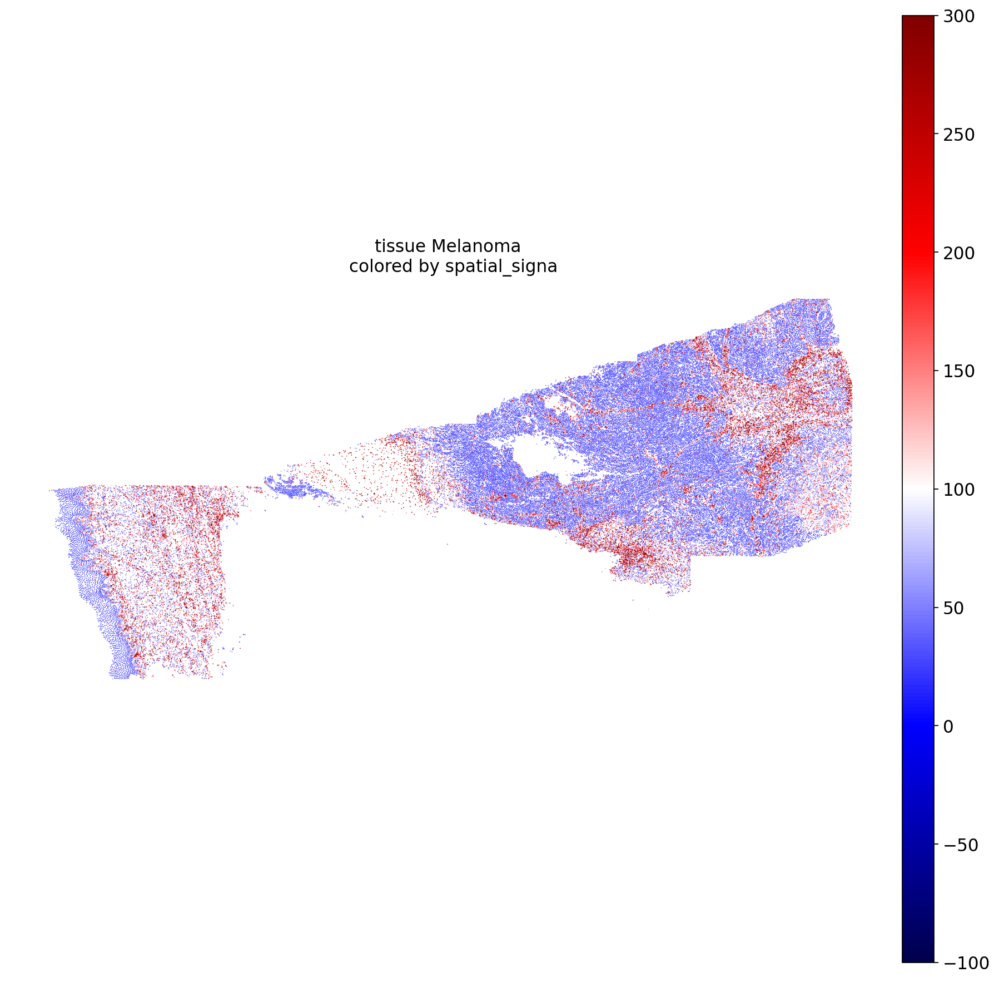

In [5]:
adata.obs['spatial_signal'] = np.sum(muxspl, 1) / np.array(adata.obsm["inflow_muxspl_before_sc_pp_normalize_total"].sum(1).tolist()).flatten()
for info_id in set(adata.obs['info_id']):
    sc.pl.spatial(
        adata[adata.obs['info_id']==info_id],
        color=['spatial_signal'],
        spot_size=10.0,
        wspace=0.5,
        #palette=sns.color_palette("Paired"),
        cmap='seismic',
        title=['tissue {} \n colored by spatial_signa'.format(info_id)],
        vmax=300,
        vmin=-100
    )

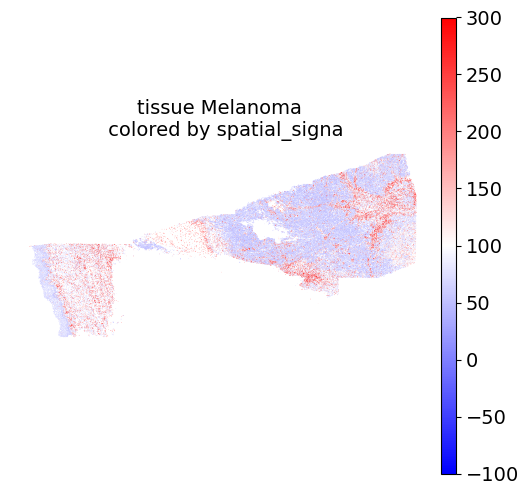

In [6]:
sc.settings.set_figure_params(dpi_save=300, dpi=50, facecolor="white", frameon=False, figsize=(6,6))

#adata.obs['spatial_signal'] = np.sum(muxspl, 1) / np.array(adata.X.sum(1).tolist()).flatten()
adata.obs['spatial_signal'] = np.sum(muxspl, 1) / np.array(adata.obsm["inflow_muxspl_before_sc_pp_normalize_total"].sum(1).tolist()).flatten()
for info_id in set(adata.obs['info_id']):
    sc.pl.spatial(
        adata[adata.obs['info_id']==info_id],
        color=['spatial_signal'],
        spot_size=10.0,
        wspace=0.5,
        #palette=sns.color_palette("Paired"),
        cmap='bwr',
        title=['tissue {} \n colored by spatial_signa'.format(info_id)],
        vmax=300,
        vmin=-100,
        save="fig4a.pdf"
    )

# fig 4c

In [7]:
key_celltype="broad_celltypes"
CATEGORY = "spatial_niche"

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


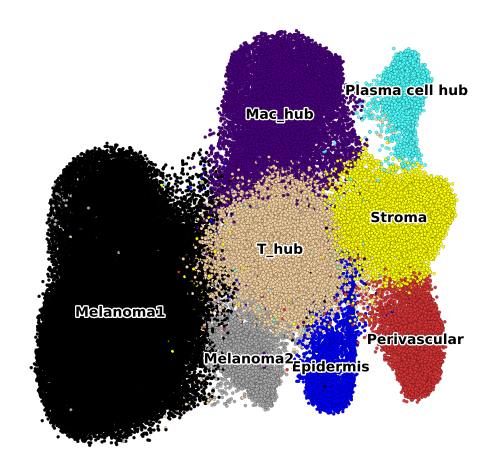

In [8]:

sc.pl.umap(
    adata,
    color=['spatial_niche'],
    s=20,
    legend_loc="on data",
    legend_fontsize=10,
    legend_fontoutline=2,
            edgecolor="black",
        linewidth=0.1,
 #   save="spatial_umap_mm.pdf",
    title=""
)


# fig 4f

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


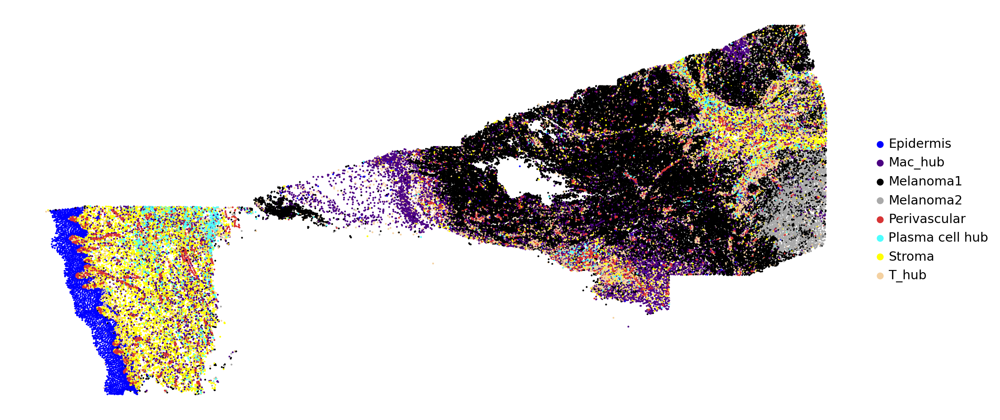

In [10]:
sc.settings.set_figure_params(dpi_save=300, facecolor="white", frameon=False, figsize=(14,14))

sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=f'spatial_niche',
        size=2,
        title='',

  #  save="spatial_by_space_size2.pdf"
    )


# fig 4j

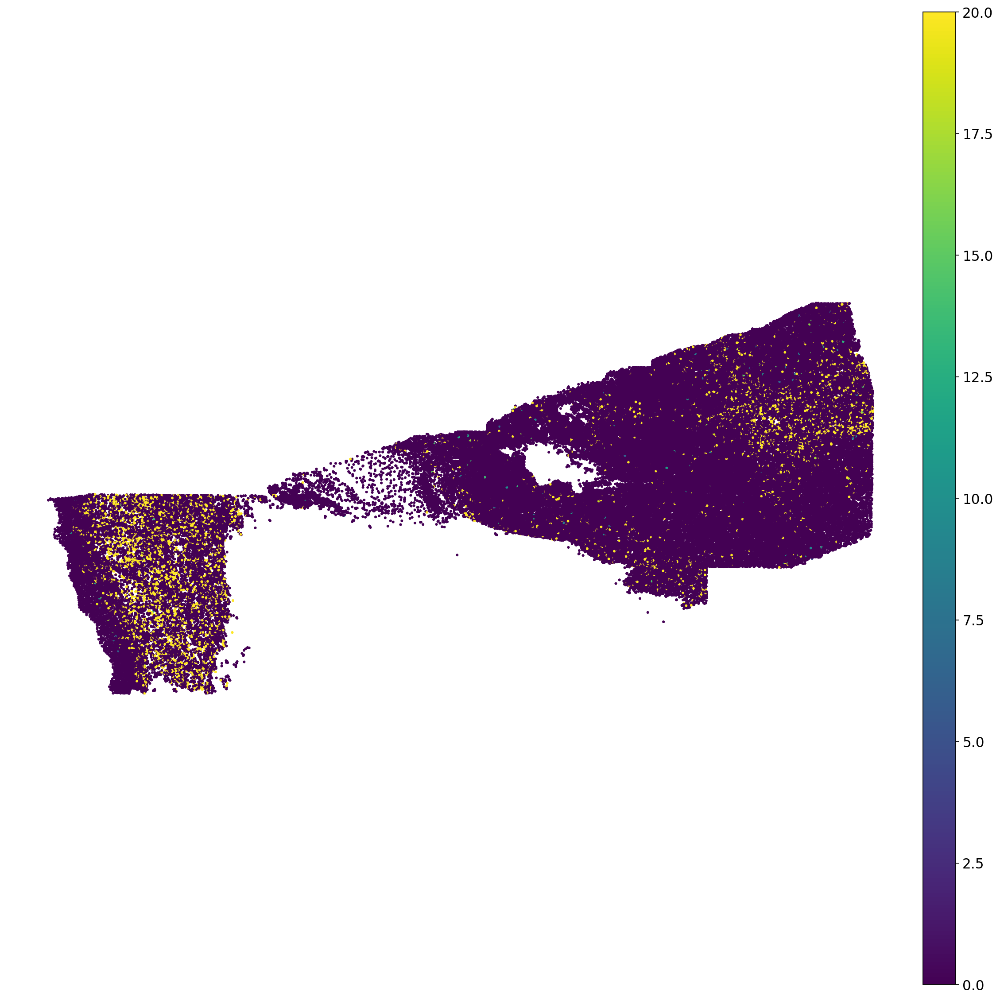

In [11]:
sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=['LOXL1'],
        size=10,
        title='',
        vmax=20,
 save="LOXL__umap.pdf"
    )


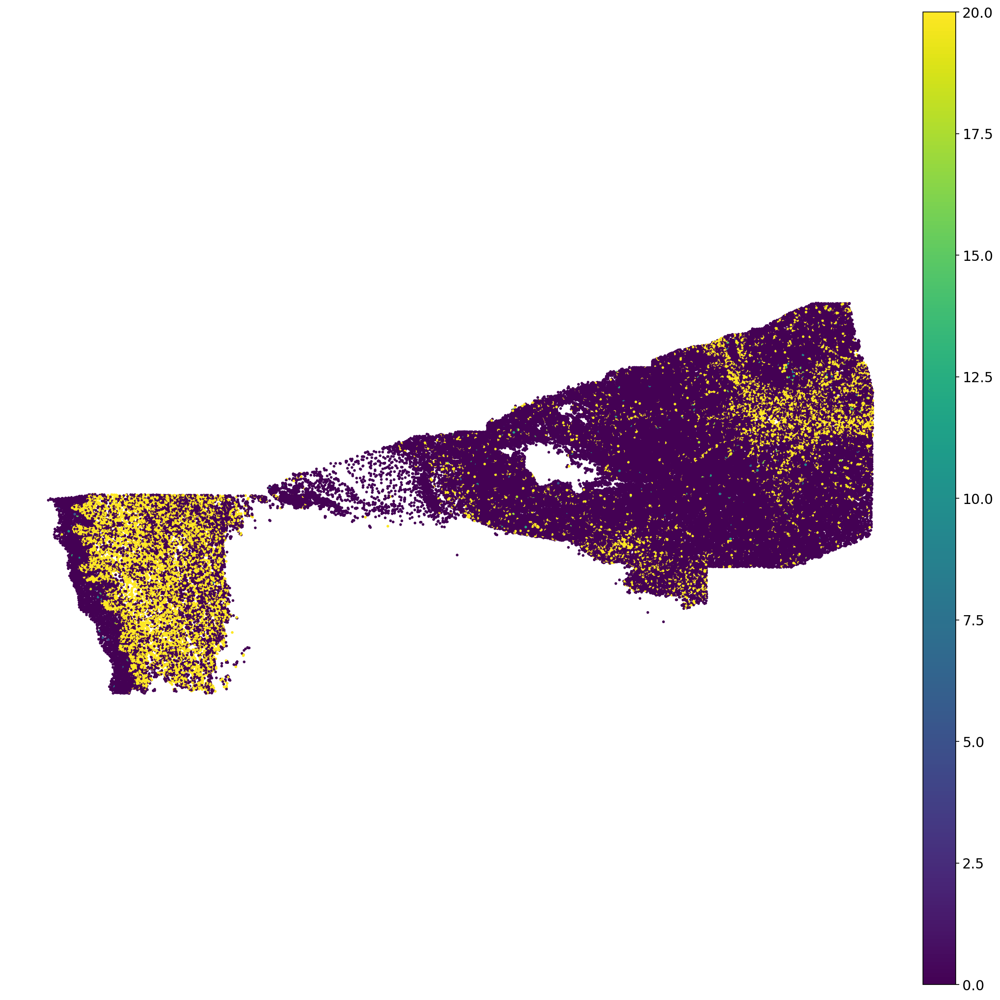

In [12]:
sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=['COL5A1'],
        size=10,
        title='',
        vmax=20,
    save="col5a1__umap.pdf"
    )


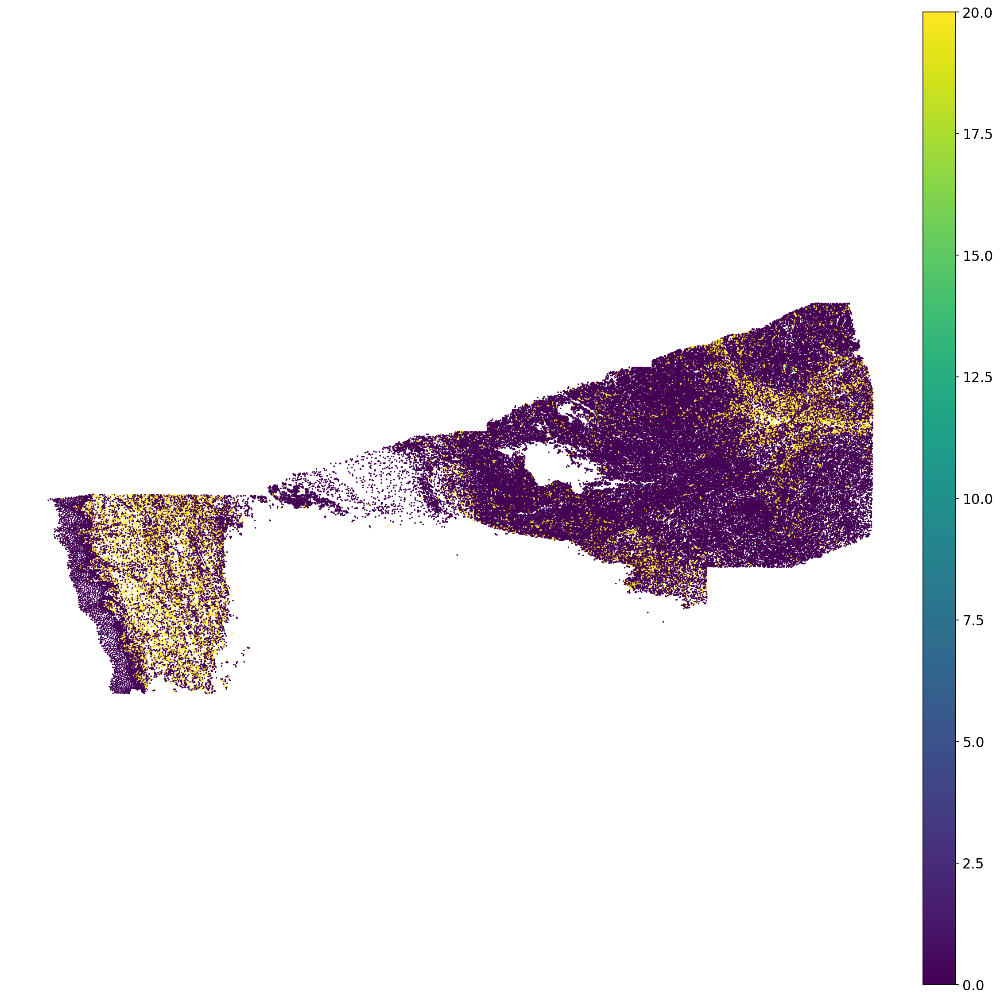

In [13]:
sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=['CXCL12'],
        size=1,
        title='',
        vmax=20,
 #   save="cxcl19__umap.pdf"
    )


# fig 4g

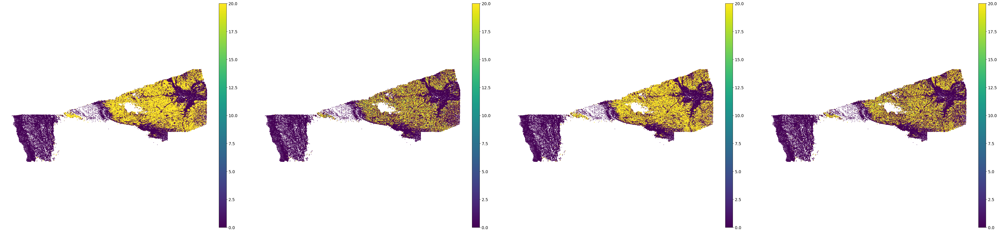

In [14]:
sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=['MLANA', 'SOX10', 'PRAME', "MELTF"],
        size=1,
        title='',
        vmax=20,
   # save="Melanoma_degs_by_space_toprow.pdf"
    )


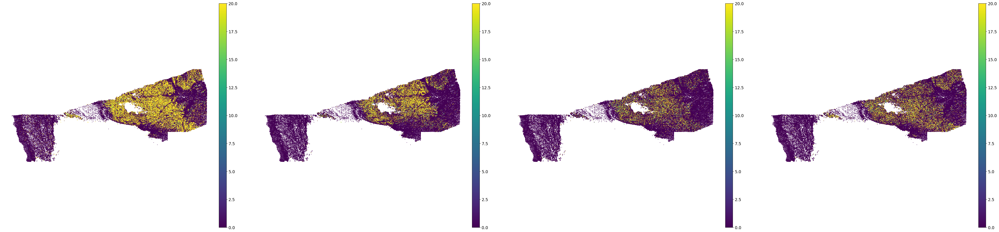

In [15]:
sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=['EDNRB', 'CST1', 'BAALC', "GDF15"],
        size=1,
        title='',
        vmax=20,
#save="Melanoma_degs_by_space_bottomrow.pdf"
    )


In [16]:
CATEGORY = 'spatial_niche'
ADATA = adata

sc.tl.rank_genes_groups(adata, CATEGORY, method='t-test', key_added="de_leiden");
df2 = pd.DataFrame(adata.uns['de_leiden']['names'])
for i,x in enumerate(df2.columns):
     print(i,":",x)


0 : Epidermis
1 : Mac_hub
2 : Melanoma1
3 : Melanoma2
4 : Perivascular
5 : Plasma cell hub
6 : Stroma
7 : T_hub


/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (


Epidermis
Mac_hub
Melanoma1
Melanoma2
Perivascular
Plasma cell hub
Stroma
T_hub


/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


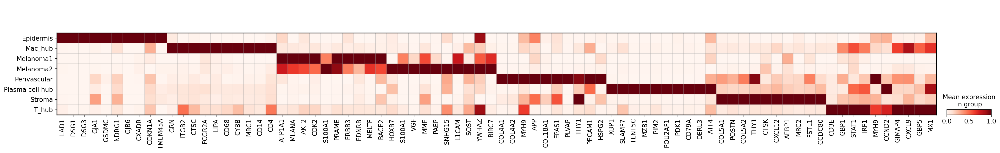

In [17]:
DEGS = []
for select_population in list(df2.columns):
    print(select_population)

    genes0 = list(df2[select_population][:10])
    DEGS.extend(genes0)


sc.pl.matrixplot(
    ADATA,
    DEGS,
    groupby=CATEGORY,
    standard_scale="var",
    dendrogram=False,
    cmap="Reds",
       # save="spatial_degs.pdf"

)
 

Stroma


/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


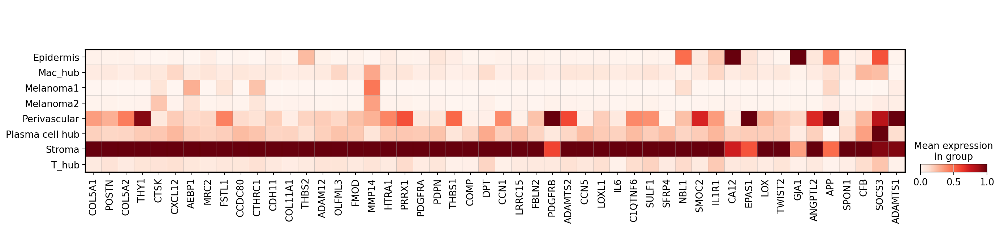

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


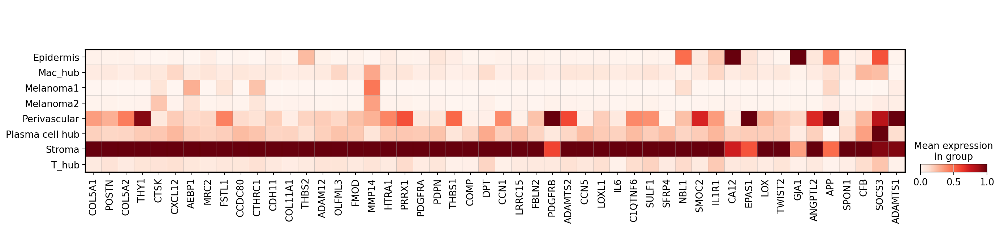

In [18]:
select_population = list(df2.columns)[-2
                                     ]
CATEGORY="spatial_niche"
print(select_population)

genes0 = df2[select_population][:50]
genes_extended = df2[select_population][0:100]
genes2 = df2[select_population][100:150]
 

sc.pl.matrixplot(
    ADATA,
    genes0,
    groupby=CATEGORY,
    standard_scale="var",
    dendrogram=False,
    cmap="Reds",
     #   save="spatial_MCP_stroma.pdf"

)


sc.pl.matrixplot(
    ADATA,
    genes0,
    groupby=CATEGORY,
    standard_scale="var",
    dendrogram=False,
    cmap="Reds",
#save="spatial_MCP_stroma_100genes.pdf"

)


/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(

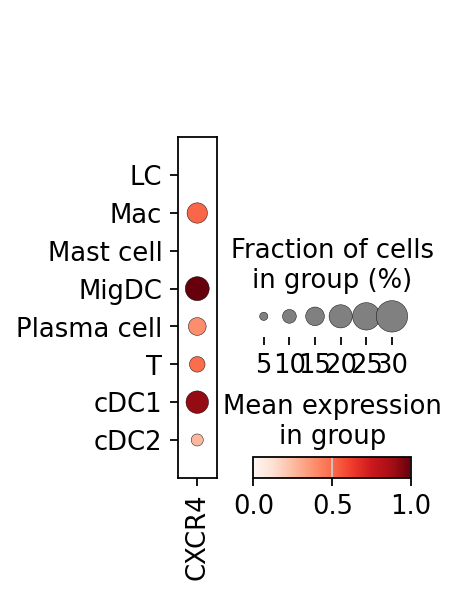

In [36]:
KEEP = [#'KCinflamm_late',
# 'KCinflamm_final',
 #'KCinflamm_int',
 #'KCinflamm_basal',
 'cDC2',
 'LC',
 'T',
 'Mast cell',
 #'Melanoma',
 #'F6: Myofibroblast inflammatory',
 #'F1: Superficial',
 'Mac',
 #'Nonspecific',
 'Plasma cell',
 #'Pericyte',
 'cDC1',
 #'LE',
 #'F6: Myofibroblast',
 #'VE',
 'MigDC']
adata_immune = adata[adata.obs[key_celltype].isin(KEEP)]
sc.pl.dotplot(
    adata_immune,
    [ "CXCR4"],
    groupby=key_celltype,
    standard_scale="var",
    dendrogram=False,
    cmap="Reds",
       # save="DOTPLOT_CXCL12_CCL19_immunecells.pdf"

)

In [21]:
colors  = {'KCinflamm_late': '#f4e9ef',
 'KCinflamm_final': '#E07090',
 'KCinflamm_int': '#007FFF',
 'KCinflamm_basal': '#f4e9ef',
 'cDC2': '#6F478C',
 'LC': '#3bc1d9',
 'T': "#FF5F00", #'#F4D1A1',
 'Mast cell': '#927D60',
 'Melanoma': "#8B5A2B",#'#3D1C02',
 #'F6: Myofibroblast inflammatory': 'Cancer-associated fibroblast',
 'Fibroblast': '#FFFFE4',
 'Mac': '#1B03A3',
 'Nonspecific': '#D3D3D3',
 'Plasma cell': '#C2F8FF',
 'Pericyte': '#F7A3C3',
 'cDC1': '#9B70C1',
 'LE': '#FFFF00',
 'Cancer-associated fibroblast':"#52aaff" ,
 'VE': '#d73435',
 'MigDC': '#00FF00'}


In [22]:
RENAME = {'KCinflamm_late': 'KCinflamm_late',
 'KCinflamm_final': 'KCinflamm_final',
 'KCinflamm_int': 'KCinflamm_int',
 'KCinflamm_basal': 'KCinflamm_basal',
 'cDC2': 'cDC2',
 'LC': 'LC',
 'T': 'T',
 'Mast cell': 'Mast cell',
 'Melanoma': 'Melanoma',
 'F6: Myofibroblast inflammatory': 'Cancer-associated fibroblast',
 'F1: Superficial': 'Fibroblast',
 'Mac': 'Mac',
 'Nonspecific': 'Nonspecific',
 'Plasma cell': 'Plasma cell',
 'Pericyte': 'Pericyte',
 'cDC1': 'cDC1',
 'LE': 'LE',
 'F6: Myofibroblast': 'Cancer-associated fibroblast',
 'VE': 'VE',
 'MigDC': 'MigDC'}
adata.obs["key_celltype_new"]=adata.obs[key_celltype].map(RENAME)

In [23]:
adata.obs["spatial_niche"].value_counts()

spatial_niche
Melanoma1          45819
T_hub              13882
Mac_hub            13590
Stroma              9447
Perivascular        5263
Melanoma2           3902
Plasma cell hub     3519
Epidermis           3327
Name: count, dtype: int64

In [25]:
adata=adata[adata.obs["key_celltype_new"]!="Nonspecific"]

/tmp/ipykernel_3720/2666257262.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["spatial_niche", "key_celltype_new"])
/tmp/ipykernel_3720/2666257262.py:51: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


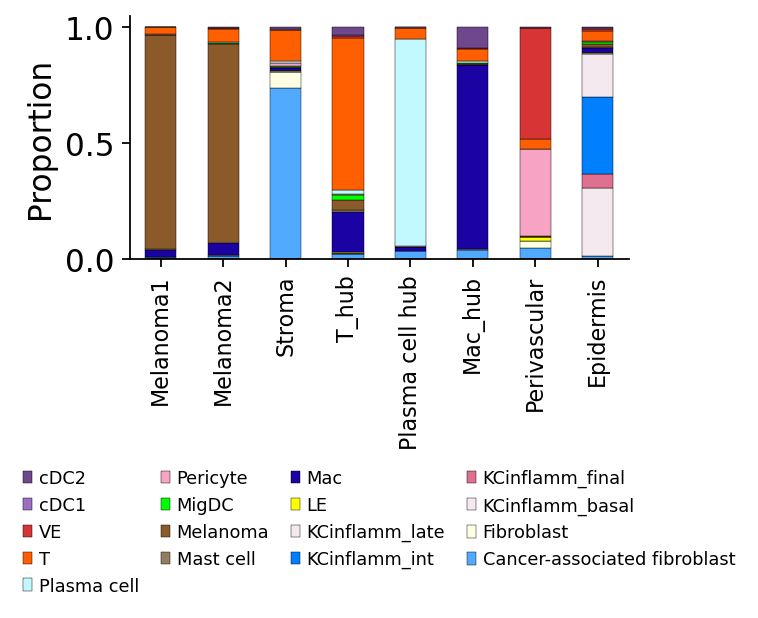

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# ---------- inputs ---------------------------------------------------------
ORDER = [
     "Melanoma1", "Melanoma2",
    "Stroma", "T_hub", 
    "Plasma cell hub", "Mac_hub", "Perivascular","Epidermis", "Blood vessel",
]
df = (
    adata.obs
        .groupby(["spatial_niche", "key_celltype_new"])
        .size()
        .unstack(fill_value=0)
)
df_norm = (
    df.div(df.sum(axis=1), axis=0)
      .loc[:, lambda c: c.mean() >= 0.002]          # keep frequent cats
      .reindex(ORDER, axis=0)
      .dropna(how="all")
)

color_list = [colors.get(cat, "#D3D3D3") for cat in df_norm.columns]

# ---------- plot -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(4, 2))
df_norm.plot(
    kind="bar", stacked=True, ax=ax,
    color=color_list, edgecolor="black", linewidth=0.2
)

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("Proportion")
plt.xticks(rotation=90, fontsize=10)     # shrink x-tick labels

# ---------- legend ---------------------------------------------------------
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1], labels[::-1],
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -.8),        # push it lower  ↓↓↓
    frameon=False,
    columnspacing=1.2, handletextpad=0.4,
    fontsize=8,                         # smaller legend text
    title="",
)

plt.tight_layout()
plt.show()

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/h

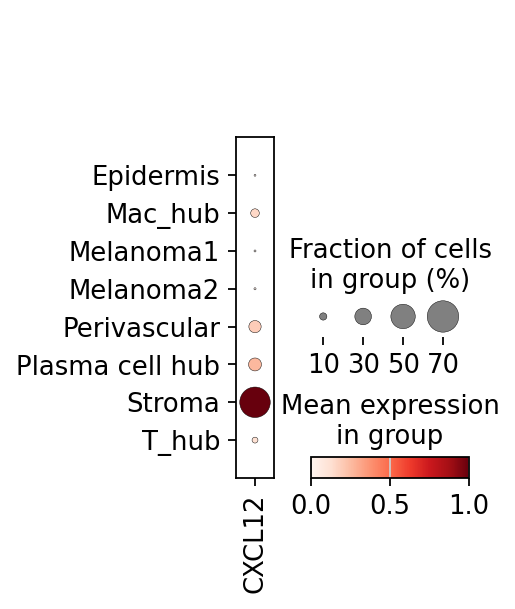

In [27]:

sc.pl.dotplot(
    adata,
    ["CXCL12"],
    groupby="spatial_niche",
    standard_scale="var",
    dendrogram=False,
)

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


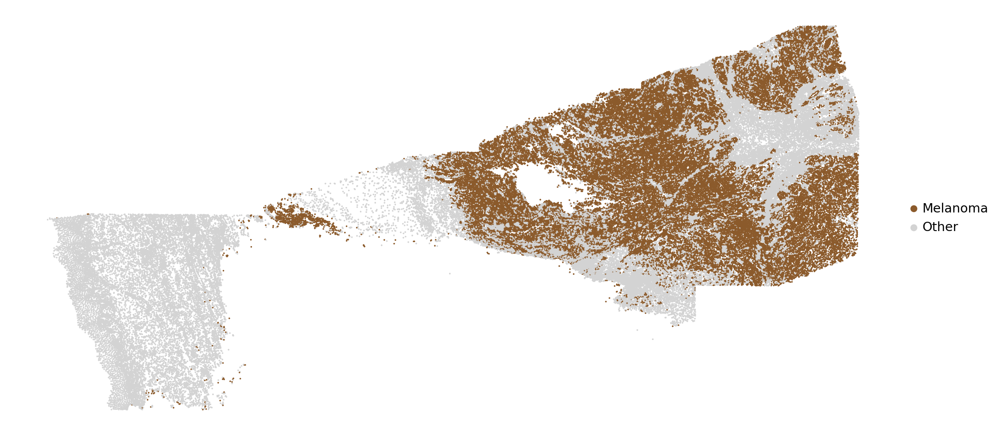

In [30]:
custom_colors = {
    "Melanoma": "#8B5A2B",  # Light brown
    "Other": "#D3D3D3"  # Light grey
}

adata.obs["mm"] = ["Melanoma" if x == "Melanoma" else "Other" for x in adata.obs[key_celltype]]
adata.obs["mm"] = adata.obs["mm"].astype("category")

adata.uns["mm_colors"] = [custom_colors[cat] for cat in adata.obs["mm"].cat.categories]
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="mm",
    size=1,
    title="",
    vmax=20,
  #  save="mm_cells.pdf"
)

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


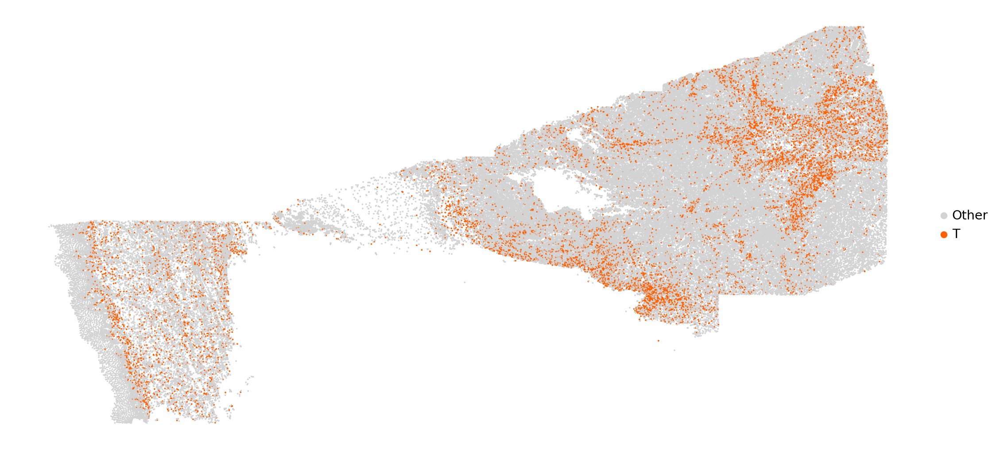

In [31]:
custom_colors = {
    "T": '#FF5F00',   # "#8B5A2B",  # Light brown
    "Other": "#D3D3D3"  # Light grey
}

adata.obs["mm"] = ["T" if x == "T" else "Other" for x in adata.obs[key_celltype]]

adata.obs["mm"] = adata.obs["mm"].astype("category")

adata.uns["mm_colors"] = [custom_colors[cat] for cat in adata.obs["mm"].cat.categories]


# Plot
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="mm",
    size=1,
    title="",
    vmax=20,
     #   save="t_cells.pdf",
)



/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


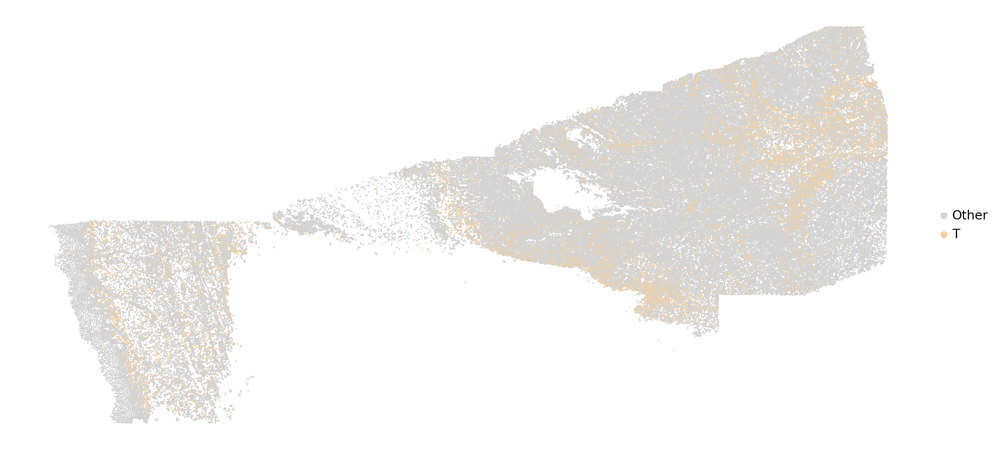

In [32]:
custom_colors = {
    "T": '#F4D1A1',   # "#8B5A2B",  # Light brown
    "Other": "#D3D3D3"  # Light grey
}

adata.obs["mm"] = ["T" if x == "T" else "Other" for x in adata.obs[key_celltype]]
adata.obs["mm"] = adata.obs["mm"].astype("category")
adata.uns["mm_colors"] = [custom_colors[cat] for cat in adata.obs["mm"].cat.categories]

sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="mm",
    size=1,
    title="",
    vmax=20,
     #   save="t_cells.pdf",
)



/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


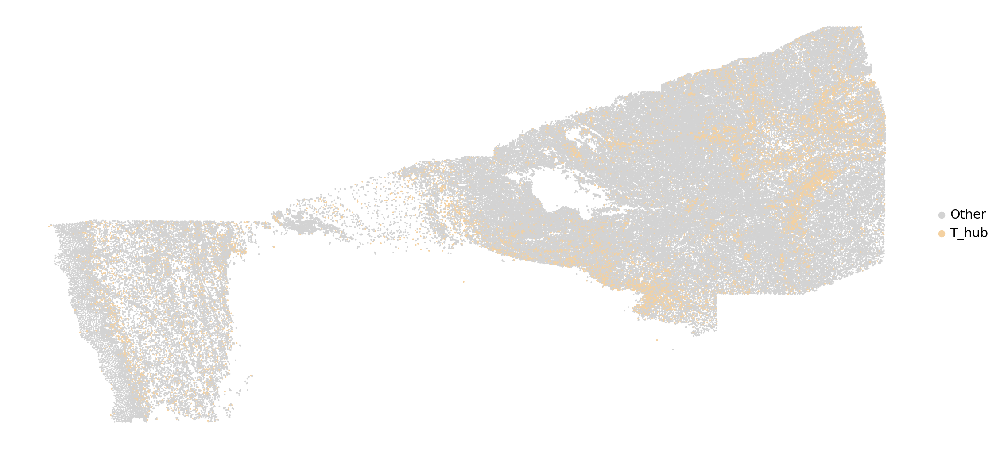

In [33]:
custom_colors = {
    "T_hub": "#F4D1A1",   # "#8B5A2B",  # Light brown
    "Other": "#D3D3D3"  # Light grey
}

adata.obs["mm"] = [x if x == "T_hub" else "Other" for x in adata.obs["spatial_niche"]]

adata.obs["mm"] = adata.obs["mm"].astype("category")

adata.uns["mm_colors"] = [custom_colors[cat] for cat in adata.obs["mm"].cat.categories]

sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="mm",
    size=1,
    title="",
    vmax=20,
      #  save="thub_cells.pdf"

    #edgecolor='black',
    #linewidth=0.1
)
  

/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
/home/jovyan/my-conda-envs/sko_ls/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


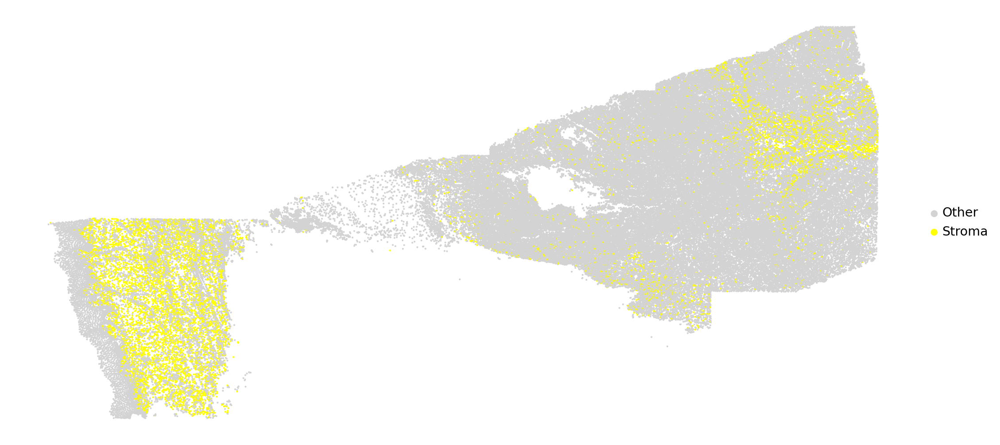

In [34]:

# Define colors for "Stroma" and "Other"
custom_colors = {
    "Stroma": "#FFFF00",  # <-- FIXED: Only one `#`
    "Other": "#D3D3D3"
}

# Assign colors to the .uns dictionary in the order they appear in the "mm" category
adata.obs["mm"] = [x if x == "Stroma" else "Other" for x in adata.obs["spatial_niche"]]

# Ensure "mm" is a categorical variable
adata.obs["mm"] = adata.obs["mm"].astype("category")

# Store the colors in .uns
adata.uns["mm_colors"] = [custom_colors[cat] for cat in adata.obs["mm"].cat.categories]

# Plot
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="mm",
    size=2,
    title="",
    vmax=20,
 #   save="stroma_cells.pdf"
)